# Demo: sequences <-> networks
The following notebook provides a demonstration how the ts2g2 library can be used to convert time series into graphs and graphs into time series. To that end, we use a dataset with the history of daily prices of Amazon stock (AMZN). All the column descriptions are provided. Currency is USD.

In [1]:
import os
import sys
nb_dir = os.path.split(os.getcwd())[0]
if nb_dir not in sys.path:
    sys.path.append(nb_dir)

In [2]:
import os
import csv
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from timeseries.strategies import TimeseriesToGraphStrategy, TimeseriesEdgeVisibilityConstraintsNatural, TimeseriesEdgeVisibilityConstraintsHorizontal, EdgeWeightingStrategyNull
from generation.strategies import RandomWalkWithRestartSequenceGenerationStrategy, RandomWalkSequenceGenerationStrategy, RandomNodeSequenceGenerationStrategy, RandomNodeNeighbourSequenceGenerationStrategy, RandomDegreeNodeSequenceGenerationStrategy
from core import model 
from sklearn.model_selection import train_test_split
import datetime

ModuleNotFoundError: No module named 'timeseries'

In [3]:
def get_timenow():
    return datetime.datetime.now()

In [4]:
def measure_timediff(start, end):
    return (end - start).microseconds

## Loading data 

We first load the dataset :)

In [5]:
# TODO: here we provide a sample dataset. We encourage the tester to load a dataset of their own!
amazon_data = pd.read_csv(os.path.join(os.getcwd(), "amazon", "AMZN.csv"))

To properly use the ‘Date’ column, we convert it to datetime format and ensure the dates are recognized as date objects. We then set the ‘Date’ column as the index of the DataFrame. This creates a time-series structure, facilitating analysis and visualization over time.

In [6]:
amazon_data["Date"] = pd.to_datetime(amazon_data["Date"])
amazon_data.set_index("Date", inplace=True)

# How does the time series look like?

In [8]:
def plot_timeseries(sequence, title, x_legend, y_legend, color):
    plt.figure(figsize=(10, 6))
    plt.plot(sequence, linestyle='-', color=color)
    
    plt.title(title)
    plt.xlabel(x_legend)
    plt.ylabel(y_legend)
    plt.grid(True)
    plt.show()

In [9]:
def plot_timeseries_sequence(df_column, title, x_legend, y_legend, color='black'):
    sequence = model.Timeseries(model.TimeseriesArrayStream(df_column)).to_sequence()
    plot_timeseries(sequence, title, x_legend, y_legend, color)

In [10]:
plot_timeseries_sequence(amazon_data["Close"], "Original Sequence", "Year", "Value")

NameError: name 'model' is not defined

Given the great length of the timeseries, let's focus on some sub-segments, so that we can better appreciate its behavior.

In [12]:
#TODO: define sequences of varying lengths. Ideally, consider cases of 100, 500, 1K, 5K or 10K+ timesteps/nodes
segment_1 = #TODO complete

SyntaxError: invalid syntax (3975941816.py, line 2)

How do the plots for these segments look like?

In [13]:
plot_timeseries_sequence(segment_1["Close"], "Segment 1", "Year", "Value", 'gray')

NameError: name 'segment_1' is not defined

Let's turn the timeseries into networks (graphs)!

In [12]:
# TODO: adapt the following method and test at least two strategies regarding visibility and weight 

def sequence_to_graph(column, color):
    strategy = TimeseriesToGraphStrategy(
        visibility_constraints=[TimeseriesEdgeVisibilityConstraintsNatural()],
        graph_type="undirected",
        edge_weighting_strategy=EdgeWeightingStrategyNull(),
    )

    g = strategy.to_graph(model.TimeseriesArrayStream(column))
    pos=nx.spring_layout(g.graph, seed=1)
    nx.draw(g.graph, pos, node_size=40, node_color=color)

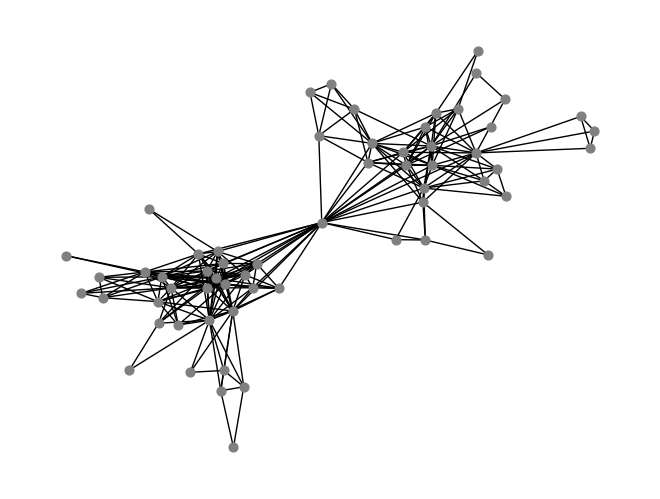

In [13]:
# TODO: how do the graphs between the different strategies differ?
# TODO: are there any differences between the segments you considered?
sequence_to_graph(segment_1["Close"], 'gray')

They look quite different! Many different strategies for converting timeseries into graphs exist:
 - TimeseriesEdgeVisibilityConstraintsNatural
 - TimeseriesEdgeVisibilityConstraintsHorizontal
 - TimeseriesEdgeVisibilityConstraintsVisibilityAngle

Now let's try to create a sequence generator, based on a graph. We will first divide each sequence into train/test sets.

In [15]:
# TODO: adapt the following method to use the same strategies you evaluated above and at least two sequence generator strategies

def generate_sequence(df, reference_column, color):
    df_train, df_test = train_test_split(df, test_size=0.2, random_state=100)
    stream_train = model.TimeseriesArrayStream(df_train[reference_column])

    strategy = TimeseriesToGraphStrategy(
        visibility_constraints=[TimeseriesEdgeVisibilityConstraintsNatural()],
        graph_type="undirected",
        edge_weighting_strategy=EdgeWeightingStrategyNull(),
    )
    graph = strategy.to_graph(stream_train)
    test_length = len(df_test.index)
    sequence = graph.to_sequence(RandomWalkWithRestartSequenceGenerationStrategy(), sequence_length=test_length)
    
    dfx = pd.DataFrame(
    {'y_true': df[reference_column].values,
     'y_pred': [None]*len(df_train.index)+sequence
    })
    dfx.index = df.index
    plt.figure(figsize=(10, 6))  # Set the figure size
    plt.plot(dfx['y_true'], linestyle='-.', color=color)
    plt.plot(dfx['y_pred'], linestyle='-', color='black')
    plt.title("Random Walk With Restart Sequence Generated Strategy")
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.grid(False)
    plt.show()

In [16]:
# TODO: evaluate sequence generation on your own sequences and strategies
# TODO: do the results look promising?
generate_sequence(segment_1, 'Close', 'gray')

NameError: name 'segment_1' is not defined

Many additional strategies for converting graphs to timeseries exist: 
 - RandomWalkWithRestartSequenceGenerationStrategy
 - RandomWalkSequenceGenerationStrategy
 - RandomNodeSequenceGenerationStrategy
 - RandomDegreeNodeSequenceGenerationStrategy
 - RandomDegreeNodeSequenceGenerationStrategy
 - RandomNodeNeighbourSequenceGenerationStrategy